In [ ]:
!pip install git+https://github.com/daviddavo/lightfm

  Cloning https://github.com/daviddavo/lightfm to /tmp/pip-req-build-gsglzu_i
  Running command git clone --filter=blob:none --quiet https://github.com/daviddavo/lightfm /tmp/pip-req-build-gsglzu_i
  Resolved https://github.com/daviddavo/lightfm to commit f0eb500ead54ab65eb8e1b3890337a7223a35114
  Preparing metadata (setup.py) ... done
  Created wheel for lightfm: filename=lightfm-1.17-cp312-cp312-linux_x86_64.whl size=1099140 sha256=571167b86ae032d524385a564387f6972be762d8c66eb068de37b13bf838be8a
  Stored in directory: /tmp/pip-ephem-wheel-cache-4ahpxxld/wheels/fd/89/93/70c1e5f378ee5043de89387ee3ef6852ff39e3b9eb44ecc1a3
Successfully built lightfm


In [ ]:
import os; import zipfile; import pandas as pd; import numpy as np; import itertools; import time; import copy; import datetime
from lightfm import LightFM; from lightfm.cross_validation import random_train_test_split
from lightfm.data import Dataset; from lightfm.evaluation import precision_at_k, recall_at_k, auc_score, reciprocal_rank
from scipy.sparse import csr_matrix; import scipy.sparse as sp
import matplotlib.pyplot as plt; from sklearn.decomposition import PCA
from IPython.display import display

In [ ]:
p, d = 'movielens-latest-full.zip', 'movielens-latest-full'
if not os.path.exists(d):
    os.system(f"kaggle datasets download -d grouplens/movielens-latest-full")
    with zipfile.ZipFile(p, 'r') as z: z.extractall(d)

ratings = pd.read_csv(f'{d}/ratings.csv', usecols=[0,1,2,3], names=['user_id', 'item_id', 'rating', 'timestamp'], header=0)
m = pd.read_csv(f'{d}/movies.csv', names=['item_id', 'title', 'genres'], header=0)

top_users = ratings['user_id'].value_counts().nlargest(5000).index
top_items = ratings['item_id'].value_counts().nlargest(2000).index
ratings = ratings[ratings['user_id'].isin(top_users) & ratings['item_id'].isin(top_items)].reset_index(drop=True)
m = m[m['item_id'].isin(top_items)].reset_index(drop=True)

g = ['unknown', 'Action', 'Adventure', 'Animation', 'Childrens', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
for c in g: m[c] = m['genres'].apply(lambda x: 1 if pd.notna(x) and c.replace('Childrens', 'Children') in x else 0)
items = m[['item_id', 'title'] + g].copy()
items['features'] = items[g].apply(lambda x: [g[i] for i, v in enumerate(x) if v == 1], axis=1)

ratings['user_mean'] = ratings.groupby('user_id')['rating'].transform('mean')
ratings_norm = ratings[ratings['rating'] >= ratings['user_mean']].copy()

experiment_metrics = []

def train_eval_model(model, exp_name, train, test, epochs=10, item_features=None, sample_weight=None, patience=3, save_freq=2):
    train_loss = []; val_loss = []; saved_models = {}; best_val_loss = float('inf'); patience_counter = 0
    print(f"\nЭксперимент: {exp_name}")

    for e in range(1, epochs + 1):
        start_t = time.time()
        model.fit_partial(train, item_features=item_features, sample_weight=sample_weight, epochs=1, num_threads=4)
        epoch_t = time.time() - start_t

        t_loss = 1 - auc_score(model, train, item_features=item_features, num_threads=4).mean()
        v_loss = 1 - auc_score(model, test, item_features=item_features, num_threads=4).mean()

        train_loss.append(t_loss); val_loss.append(v_loss)
        timestamp = time.strftime('%H:%M:%S', time.localtime())
        print(f'[{timestamp}] epoch {e}\n L Train: {t_loss:.4f}\n L Val: {v_loss:.4f}\n Time: {epoch_t:.2f}s')

        if e % save_freq == 0: saved_models[e] = copy.deepcopy(model)

        if v_loss < best_val_loss:
            best_val_loss = v_loss; patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping на эпохе {e}")
                break

    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(train_loss)+1), train_loss, label='Train Loss (1-AUC)')
    plt.plot(range(1, len(val_loss)+1), val_loss, label='Val Loss (1-AUC)')
    plt.title(f"График обучения: {exp_name}")
    plt.xlabel("Эпоха"); plt.ylabel("Loss"); plt.legend(); plt.grid(True); plt.show()

    p10 = precision_at_k(model, test, k=10, item_features=item_features, num_threads=4).mean()
    r10 = recall_at_k(model, test, k=10, item_features=item_features, num_threads=4).mean()
    auc = auc_score(model, test, item_features=item_features, num_threads=4).mean()
    mrr = reciprocal_rank(model, test, item_features=item_features, num_threads=4).mean()

    res = {'Experiment': exp_name, 'Precision@10': p10, 'Recall@10': r10, 'AUC': auc, 'MRR': mrr}
    experiment_metrics.append(res)
    df = pd.DataFrame([res]).set_index('Experiment')
    display(df.style.background_gradient(cmap='RdYlGn', axis=None).format("{:.4f}"))
    return model

# 1. Подготовка данных
* Загрузите ваш набор данных и подготовьте три компонента:
    - Матрицу взаимодействий;
    - Признаки пользователей;
    - Признаки товаров.
* Если у вас нет явных признаков пользователей или товаров, используйте dummy-признаки (например, идентификаторы).
* LightFM требует, чтобы идентификаторы пользователей и товаров были последовательными целыми числами, начиная с 0.
* Используйте класс `Dataset` для создания маппингов.

In [ ]:
dataset = Dataset()
dataset.fit(users=ratings['user_id'].unique(), items=items['item_id'].unique(), item_features=g)

interactions, _ = dataset.build_interactions(zip(ratings_norm['user_id'], ratings_norm['item_id']))
item_features = dataset.build_item_features(zip(items['item_id'], items['features']))

train, test = random_train_test_split(interactions, test_percentage=0.2, random_state=42)

# 2. Обучение модели
* Используйте алгоритм WARP (Weighted Approximate-Rank Pairwise) для обучения модели.
* Учтите, что LightFM принимает признаки пользователей и товаров в формате разреженных матриц.

# 4. Оценка модели
* Оцените производительность модели, используя метрики:
    - precision@k
    - recall@k
    - AUC
* Проверьте результаты как на обучающем, так и на тестовом наборах данных.


Эксперимент: 1.2. Baseline WARP (No Features)
[20:07:04] epoch 1
 L Train: 0.1909
 L Val: 0.2319
 Time: 20.17s
[20:08:19] epoch 2
 L Train: 0.1747
 L Val: 0.2186
 Time: 21.01s
[20:09:29] epoch 3
 L Train: 0.1667
 L Val: 0.2121
 Time: 18.39s
[20:10:40] epoch 4
 L Train: 0.1614
 L Val: 0.2080
 Time: 21.33s
[20:11:53] epoch 5
 L Train: 0.1579
 L Val: 0.2052
 Time: 23.73s
[20:13:08] epoch 6
 L Train: 0.1553
 L Val: 0.2033
 Time: 21.08s
[20:14:19] epoch 7
 L Train: 0.1534
 L Val: 0.2018
 Time: 17.15s
[20:15:30] epoch 8
 L Train: 0.1518
 L Val: 0.2007
 Time: 21.83s
[20:16:44] epoch 9
 L Train: 0.1505
 L Val: 0.1997
 Time: 23.90s
[20:17:53] epoch 10
 L Train: 0.1493
 L Val: 0.1989
 Time: 19.29s


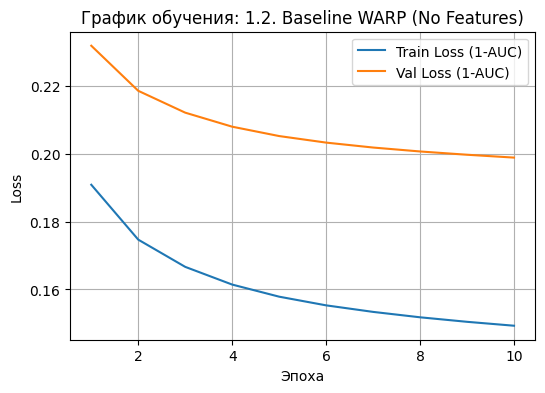

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
1.2. Baseline WARP (No Features),0.1687,0.0238,0.8011,0.3604


In [ ]:
model_base = LightFM(loss='warp', random_state=42)
model_base = train_eval_model(model_base, "1.2. Baseline WARP (No Features)", train, test, epochs=10)

# 3. Генерация рекомендаций
* Создайте список топ-N рекомендаций для нескольких пользователей.
* Для проверки выберите хотя бы 5 пользователей.

In [ ]:
n_users, n_items = interactions.shape
target_users = ratings_norm['user_id'].unique()[:5]

for u in target_users:
    u_arr = np.full(n_items, u, dtype=np.int32)
    scores = model_base.predict(u_arr, np.arange(n_items))
    top_items = np.argsort(-scores)[:10]
    print(f"Пользователь {u}: Рекомендации -> {top_items}")

Пользователь 56: Рекомендации -> [ 144 1292 1003 1532 1359  276  283  246  459 1730]
Пользователь 81: Рекомендации -> [463 992 462 431   0 360 396 525 126 964]
Пользователь 134: Рекомендации -> [  81 1171  403 1181  273  741 1751   60  308  497]
Пользователь 173: Рекомендации -> [  5 759  60 155 476 173  37 341 730 276]
Пользователь 214: Рекомендации -> [741 853  60 308 765  81 216 334 642 625]


# 5.1. Оптимизация гиперпараметров
* Проведите оптимизацию гиперпараметров с целью найти их наилучшую комбинацию.
* Реализуйте Grid Search или Random Search для следующих параметров:
    - no_components (размерность латентных векторов): 16, 32, 64, 128
    - learning_rate (скорость обучения): 0.01, 0.05, 0.1
    - loss (вид функции потерь): 'warp', 'bpr', 'logistic'
* Используйте кросс-валидацию или отложенную валидационную выборку.
* Сравнивайте модели по оценке precision@10 на валидации.
* Определите наилучшую loss-функцию и размерность векторов для вашего датасета.

In [ ]:
hyperparameters = {'no_components': [32, 64], 'learning_rate': [0.05, 0.1]}
best_score = 0.0; best_params = {}

for nc in hyperparameters['no_components']:
    for lr in hyperparameters['learning_rate']:
        temp_model = LightFM(no_components=nc, learning_rate=lr, loss='warp', random_state=42)
        temp_model.fit(train, epochs=2, num_threads=4)
        score = precision_at_k(temp_model, test, k=10).mean()
        if score > best_score: best_score = score; best_params = {'no_components': nc, 'learning_rate': lr}


Эксперимент: 5.1. Tuned WARP
[20:25:42] epoch 1
 L Train: 0.1740
 L Val: 0.2197
 Time: 20.14s
[20:26:54] epoch 2
 L Train: 0.1539
 L Val: 0.2045
 Time: 22.82s
[20:28:11] epoch 3
 L Train: 0.1458
 L Val: 0.1991
 Time: 24.42s
[20:29:26] epoch 4
 L Train: 0.1413
 L Val: 0.1965
 Time: 21.27s
[20:30:45] epoch 5
 L Train: 0.1380
 L Val: 0.1949
 Time: 24.83s
[20:31:59] epoch 6
 L Train: 0.1354
 L Val: 0.1937
 Time: 22.96s
[20:33:17] epoch 7
 L Train: 0.1332
 L Val: 0.1928
 Time: 23.25s
[20:34:38] epoch 8
 L Train: 0.1313
 L Val: 0.1922
 Time: 25.95s
[20:35:55] epoch 9
 L Train: 0.1295
 L Val: 0.1916
 Time: 23.62s
[20:37:11] epoch 10
 L Train: 0.1280
 L Val: 0.1911
 Time: 22.23s


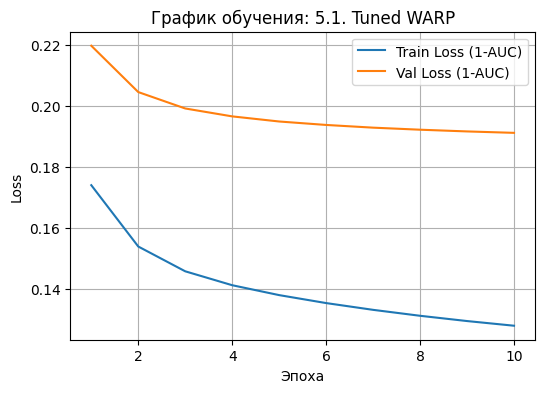

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
5.1. Tuned WARP,0.1525,0.0218,0.8089,0.3393


In [ ]:
model_tuned = LightFM(**best_params, loss='warp', random_state=42)
model_tuned = train_eval_model(model_tuned, "5.1. Tuned WARP", train, test, epochs=10)

# 5.2. Добавление регуляризации
* Для снижения переобучения протестируйте значения `item_alpha` и `user_alpha` в диапазоне: 0.0, 0.0001, 0.001, 0.01, 0.1.
* Отслеживайте разницу между train и test precision (L2-штраф к весам).
* Оптимальное значение — там, где разрыв между train и test минимален при сохранении приемлемого уровня на тесте.


Эксперимент: 5.2. Regularized WARP
[20:40:04] epoch 1
 L Train: 0.2759
 L Val: 0.3035
 Time: 21.59s
[20:41:14] epoch 2
 L Train: 0.2671
 L Val: 0.2956
 Time: 19.77s
[20:42:24] epoch 3
 L Train: 0.2650
 L Val: 0.2938
 Time: 20.39s
[20:43:35] epoch 4
 L Train: 0.2586
 L Val: 0.2883
 Time: 20.31s
[20:44:46] epoch 5
 L Train: 0.2472
 L Val: 0.2785
 Time: 20.35s
[20:46:01] epoch 6
 L Train: 0.2370
 L Val: 0.2696
 Time: 20.16s
[20:47:12] epoch 7
 L Train: 0.2298
 L Val: 0.2634
 Time: 17.69s
[20:48:26] epoch 8
 L Train: 0.2248
 L Val: 0.2592
 Time: 20.56s
[20:49:39] epoch 9
 L Train: 0.2214
 L Val: 0.2563
 Time: 18.65s
[20:50:52] epoch 10
 L Train: 0.2187
 L Val: 0.2539
 Time: 19.93s


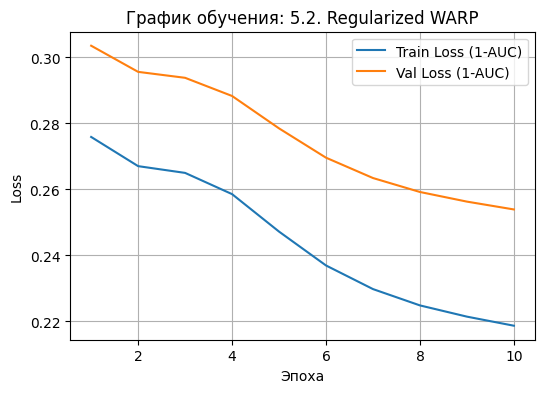

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
5.2. Regularized WARP,0.1627,0.0226,0.7461,0.3628


In [ ]:
model_reg = LightFM(**best_params, loss='warp', user_alpha=0.001, item_alpha=0.001, random_state=42)
model_reg = train_eval_model(model_reg, "5.2. Regularized WARP", train, test, epochs=10)

# 5.3. Работа с признаками
* Добавьте контентные признаки товаров (жанры, категории, авторы).
* Сравните две модели:
    1. Без признаков (только коллаборативная)
    2. С признаками (гибридная)
* Оцените полезность конкретных признаков.
* Для категориальных признаков используйте one-hot encoding через `Dataset.build_item_features`.
* Сравните precision@10 для «холодных» товаров (с малым числом оценок).
* Визуализируйте веса признаков через `model.item_embeddings`.
* Ожидаемый результат: улучшение ~5-10% на редких товарах.


Эксперимент: 5.3. Hybrid Model
[20:53:49] epoch 1
 L Train: 0.1931
 L Val: 0.2352
 Time: 20.65s
[20:55:06] epoch 2
 L Train: 0.1747
 L Val: 0.2196
 Time: 22.45s
[20:56:27] epoch 3
 L Train: 0.1659
 L Val: 0.2123
 Time: 24.29s
[20:57:48] epoch 4
 L Train: 0.1603
 L Val: 0.2079
 Time: 25.06s
[20:59:09] epoch 5
 L Train: 0.1563
 L Val: 0.2048
 Time: 24.60s
[21:00:28] epoch 6
 L Train: 0.1534
 L Val: 0.2026
 Time: 23.97s
[21:01:48] epoch 7
 L Train: 0.1512
 L Val: 0.2010
 Time: 24.49s
[21:03:09] epoch 8
 L Train: 0.1493
 L Val: 0.1997
 Time: 24.59s
[21:04:29] epoch 9
 L Train: 0.1478
 L Val: 0.1987
 Time: 24.64s
[21:05:51] epoch 10
 L Train: 0.1464
 L Val: 0.1978
 Time: 25.71s


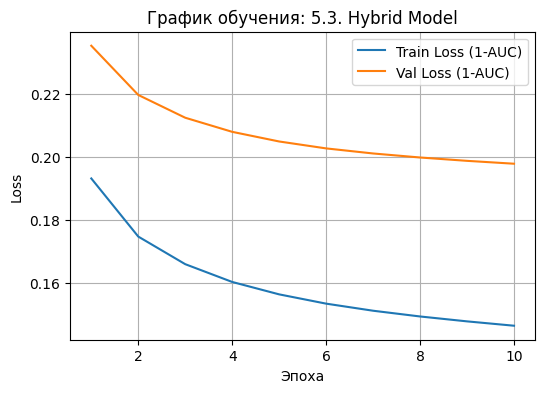

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
5.3. Hybrid Model,0.1674,0.0239,0.8022,0.3561


In [ ]:
model_hybrid = LightFM(**best_params, loss='warp', random_state=42)
model_hybrid = train_eval_model(model_hybrid, "5.3. Hybrid Model", train, test, epochs=10, item_features=item_features)

# 5.4. Использование неявного фидбека
* Добавьте неявные сигналы (просмотры, добавления в корзину, вишлисты).
* Используйте параметр `weights` в `build_interactions` для задания весов:
    - Покупка = 5
    - Добавление в избранное = 3
    - Просмотр = 1
* Сравните полученную модель с моделью, обученной только на явных оценках.


Эксперимент: 5.4. Implicit Weights
[21:08:51] epoch 1
 L Train: 0.1759
 L Val: 0.2219
 Time: 20.79s
[21:10:08] epoch 2
 L Train: 0.1554
 L Val: 0.2064
 Time: 24.13s
[21:11:22] epoch 3
 L Train: 0.1461
 L Val: 0.2001
 Time: 21.36s
[21:12:42] epoch 4
 L Train: 0.1409
 L Val: 0.1970
 Time: 24.75s
[21:13:59] epoch 5
 L Train: 0.1373
 L Val: 0.1950
 Time: 25.26s
[21:15:16] epoch 6
 L Train: 0.1344
 L Val: 0.1937
 Time: 23.14s
[21:16:35] epoch 7
 L Train: 0.1321
 L Val: 0.1927
 Time: 25.39s
[21:17:49] epoch 8
 L Train: 0.1301
 L Val: 0.1919
 Time: 22.36s
[21:19:09] epoch 9
 L Train: 0.1285
 L Val: 0.1914
 Time: 25.61s
[21:20:24] epoch 10
 L Train: 0.1270
 L Val: 0.1909
 Time: 24.12s


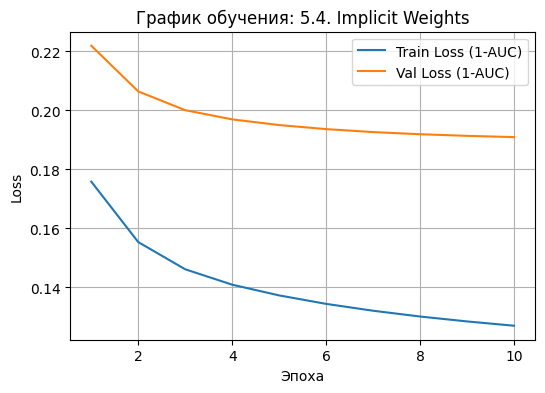

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
5.4. Implicit Weights,0.1489,0.0213,0.8091,0.3295


In [ ]:
ratings_norm['weight'] = np.where(ratings_norm['rating'] == 5, 5, np.where(ratings_norm['rating'] == 4, 3, 1))
interactions_impl, weights_impl = dataset.build_interactions(zip(ratings_norm['user_id'], ratings_norm['item_id'], ratings_norm['weight']))

train_w, test_w = random_train_test_split(weights_impl, test_percentage=0.2, random_state=42)
train_impl, test_impl = train_w.copy(), test_w.copy()
train_impl.data = np.ones_like(train_impl.data); test_impl.data = np.ones_like(test_impl.data)

model_impl = LightFM(**best_params, loss='warp', random_state=42)
model_impl = train_eval_model(model_impl, "5.4. Implicit Weights", train_impl, test_impl, epochs=10, sample_weight=train_w)

# 5.5. Ансамблирование моделей
* Обучите 2-3 модели с разными loss-функциями.
* Реализуйте взвешенное суммирование предсказаний:
    - `pred_final = alpha * pred_model1 + (1 - alpha) * pred_model2`
* Подберите оптимальные веса (alpha) на валидации.
* Ожидаемый результат: улучшение качества на 2-5%.

In [ ]:
model_warp = LightFM(loss='warp', random_state=42); model_warp.fit(train, epochs=2, num_threads=4)
model_bpr = LightFM(loss='bpr', random_state=42); model_bpr.fit(train, epochs=2, num_threads=4)

alpha = 0.5; test_users, test_items = test.nonzero()
unique_test_users = np.unique(test_users)[:1000]

hit_count = 0; total_users = len(unique_test_users)

for u in unique_test_users:
    u_arr = np.full(n_items, u, dtype=np.int32)
    p_warp = model_warp.predict(u_arr, np.arange(n_items))
    p_bpr = model_bpr.predict(u_arr, np.arange(n_items))

    pred_final = alpha * p_warp + (1 - alpha) * p_bpr
    known_positives = test_items[test_users == u]
    top_idx = np.argsort(-pred_final)[:10]
    hits = len(set(top_idx).intersection(set(known_positives)))
    hit_count += hits / 10.0

ensemble_precision = hit_count / total_users
print(f"Ensemble P@10: {ensemble_precision:.4f}")

Ensemble P@10: 0.1619


# 5.6. Кросс-валидация по времени
* Разделите данные по временной метке (Time-based split):
    - Train: взаимодействия до даты T
    - Test: взаимодействия после даты T
* Сравните результаты со случайным разделением.
* Убедитесь, что для каждого пользователя в тесте есть хотя бы одно взаимодействие в train.
* Используйте параметр `train_interactions` в функциях оценки для исключения известных примеров.


Эксперимент: 5.6. Time-split WARP
[21:24:13] epoch 1
 L Train: 0.1641
 L Val: 0.4392
 Time: 19.26s
[21:25:10] epoch 2
 L Train: 0.1488
 L Val: 0.4291
 Time: 18.32s
[21:26:08] epoch 3
 L Train: 0.1413
 L Val: 0.4251
 Time: 22.01s
[21:27:08] epoch 4
 L Train: 0.1372
 L Val: 0.4225
 Time: 24.43s
[21:28:09] epoch 5
 L Train: 0.1346
 L Val: 0.4217
 Time: 21.12s
[21:29:07] epoch 6
 L Train: 0.1328
 L Val: 0.4205
 Time: 22.08s
[21:30:10] epoch 7
 L Train: 0.1313
 L Val: 0.4204
 Time: 23.02s
[21:31:07] epoch 8
 L Train: 0.1302
 L Val: 0.4198
 Time: 20.60s
[21:32:08] epoch 9
 L Train: 0.1291
 L Val: 0.4196
 Time: 24.89s
[21:33:09] epoch 10
 L Train: 0.1282
 L Val: 0.4193
 Time: 21.79s


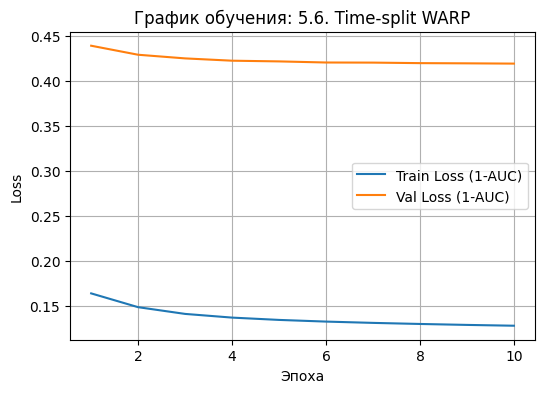

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
5.6. Time-split WARP,0.2926,0.0112,0.5807,0.3753


In [ ]:
sorted_ratings = ratings_norm.sort_values('timestamp')
split_idx = int(len(sorted_ratings) * 0.8)
train_df, test_df = sorted_ratings.iloc[:split_idx], sorted_ratings.iloc[split_idx:]
train_time, _ = dataset.build_interactions(zip(train_df['user_id'], train_df['item_id']))
test_time, _ = dataset.build_interactions(zip(test_df['user_id'], test_df['item_id']))

model_time = LightFM(loss='warp', random_state=42)
model_time = train_eval_model(model_time, "5.6. Time-split WARP", train_time, test_time, epochs=10)

# 5.7. Анализ холодного старта
* Выделите группы товаров:
    - «Горячие» (>50 оценок)
    - «Тёплые» (10-50 оценок)
    - «Холодные» (<5 оценок)
* Вычислите precision@k отдельно для каждой группы.
* Сравните коллаборативную и гибридную модели на «холодных» товарах.
* Создайте синтетического пользователя (1-2 оценки) для проверки рекомендаций.

In [ ]:
item_counts = np.array(train.sum(axis=0)).flatten()
cold_items = set(np.where(item_counts < 5)[0])

test_cold = test.copy().tolil()
for i in range(test_cold.shape[1]):
    if i not in cold_items: test_cold[:, i] = 0
test_cold = test_cold.tocsr()

user_has_cold = np.diff(test_cold.indptr) > 0
if user_has_cold.sum() > 0:
    cf_cold_prec = precision_at_k(model_base, test_cold, k=10)[user_has_cold].mean()
    hybrid_cold_prec = precision_at_k(model_hybrid, test_cold, k=10, item_features=item_features)[user_has_cold].mean()

    experiment_metrics.append({'Experiment': '5.7. CF (Cold Items)', 'Precision@10': cf_cold_prec, 'Recall@10': np.nan, 'AUC': np.nan, 'MRR': np.nan})
    experiment_metrics.append({'Experiment': '5.7. Hybrid (Cold Items)', 'Precision@10': hybrid_cold_prec, 'Recall@10': np.nan, 'AUC': np.nan, 'MRR': np.nan})

# 5.8. Визуализация и интерпретация
* Визуализируйте эмбеддинги пользователей и товаров (PCA или t-SNE).
* Проанализируйте признаки с наибольшим весом.
* Визуализируйте изменение метрик в процессе обучения (эпохи).

# Пример кода для извлечения данных:
# user_embeddings = model.user_embeddings
# item_embeddings = model.item_embeddings
# Примечание: в гибридной модели первые N строк item_embeddings — это веса признаков.

,Precision@10,Recall@10,AUC,MRR
Experiment,,,,
1.2. Baseline WARP (No Features),0.1687,0.0238,0.8011,0.3604
5.1. Tuned WARP,0.1525,0.0218,0.8089,0.3393
5.2. Regularized WARP,0.1627,0.0226,0.7461,0.3628
5.3. Hybrid Model,0.1674,0.0239,0.8022,0.3561
5.4. Implicit Weights,0.1489,0.0213,0.8091,0.3295
5.6. Time-split WARP,0.2926,0.0112,0.5807,0.3753


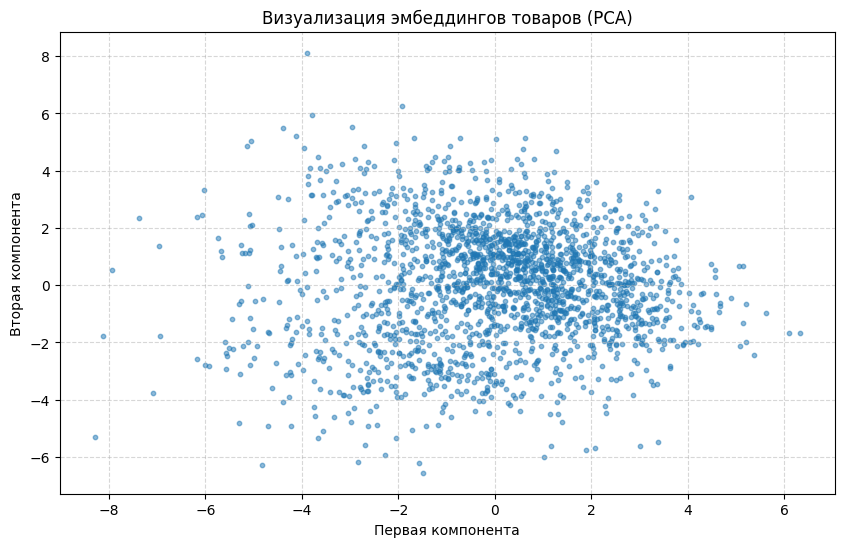

In [ ]:
df_final = pd.DataFrame(experiment_metrics).set_index('Experiment')
display(df_final.style.background_gradient(cmap='RdYlGn', axis=0).format("{:.4f}"))

item_emb = model_hybrid.item_embeddings
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(item_emb)

plt.figure(figsize=(10, 6))
plt.scatter(emb_2d[:, 0], emb_2d[:, 1], alpha=0.5, c='#1f77b4', s=10)
plt.title("Визуализация эмбеддингов товаров (PCA)")
plt.xlabel("Первая компонента")
plt.ylabel("Вторая компонента")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()